<a href="https://colab.research.google.com/github/Anna-Zamriy/MN/blob/main/%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D0%97%D0%B0%D0%BC%D1%80%D1%96%D0%B9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**
**ПІБ студента:** Замрій  Анна Олегівна
**Група:** ФІТ 3-8  
**Дата:** 13.11

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Це набір характеристик пацієнта, які використовуються для визначення, чи має людина діабет.

gender містить стать пацієнта (чоловіча, жіноча або інша).
age показує вік у роках.

hypertension вказує на наявність гіпертонії: 0 означає відсутність підвищеного тиску, 1 означає його наявність.

heart_disease показує, чи має пацієнт серцево-судинні захворювання: 0 для «ні», 1 для «так».

smoking_history описує історію куріння: людина ніколи не курила, курила раніше, курить зараз, не курить наразі або інформація невідома.

bmi (індекс маси тіла) характеризує співвідношення ваги до зросту.

HbA1c_level відображає середній рівень цукру в крові за останні 2–3 місяці через показник глікозильованого гемоглобіну.

blood_glucose_level містить поточний рівень глюкози в крові на момент вимірювання.

diabetes є цільовою ознакою набору даних і показує результат: 0 означає, що діабету немає, а 1 означає, що діабет діагностовано.

Вивести інформацію про датасет

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [5]:
df.value_counts('gender')

,count
gender,
Female,58552
Male,41430
Other,18


In [6]:
df.value_counts('smoking_history')

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [7]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [8]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [9]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [10]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [11]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [14]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

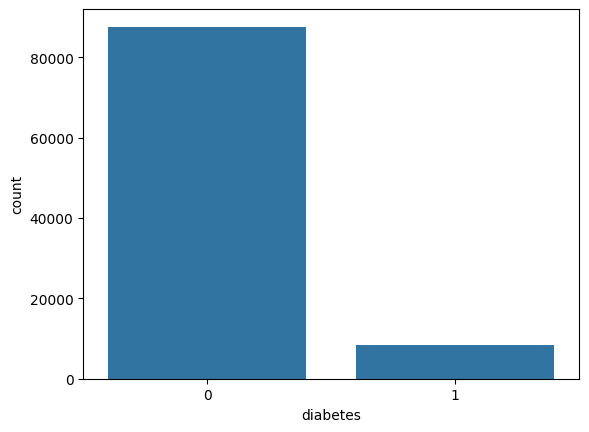

In [15]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [16]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [17]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# Зберігаємо співвідношення класів у train і test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [18]:
# Кодуюємо категорії окремо для train і test.
cat_cols = ['gender', 'smoking_history']
X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print('Ознак після кодування:', X_train.shape[1])

Ознак після кодування: 15


In [19]:
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [20]:
# Використовуємо тільки X_train та y_train.
X_train.corrwith(y_train).sort_values(ascending=False)

,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


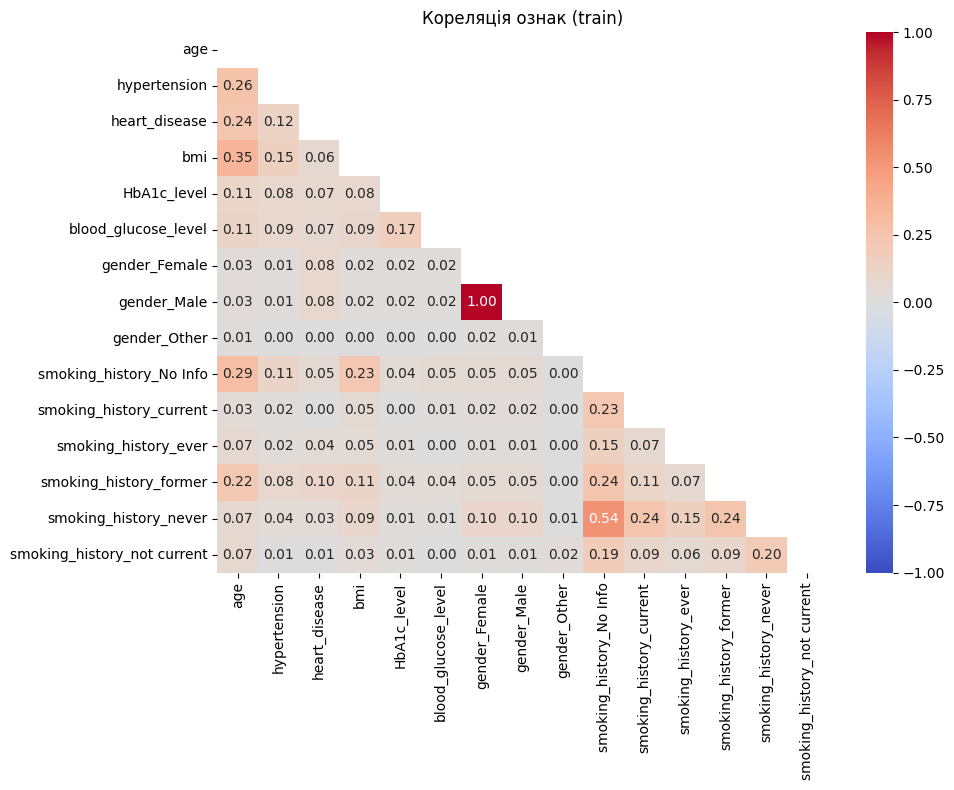

In [21]:
# Кореляція між ознаками навчальної вибірки
mtx = X_train.corr(numeric_only=True).abs()

plt.figure(figsize=(10, 8))
sns.heatmap(mtx, cmap='coolwarm', annot=True, fmt='.2f',
            mask=np.triu(np.ones_like(mtx, dtype=bool)),
            vmin=-1, vmax=1)
plt.title('Кореляція ознак (train)')
plt.tight_layout()
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

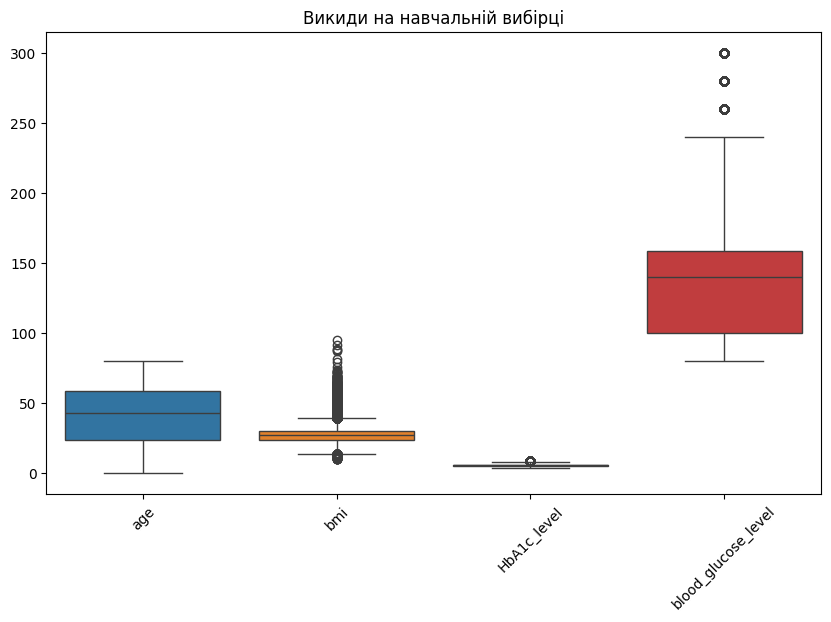

In [22]:
# Аналізуємо неперервні показники, а не закодовані категорії.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.xticks(rotation=45)
plt.title('Викиди на навчальній вибірці')
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# Приклад для однієї ознаки ('bmi') – не виконуємо в цій роботі:
q1 = X_train['bmi'].quantile(0.25)
q3 = X_train['bmi'].quantile(0.75)
iqr = q3 - q1
mask = X_train['bmi'].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
X_train = X_train.loc[mask].copy()
y_train = y_train.loc[mask].copy()

Перевірити асиметрію розподілів ознак **на train**

In [24]:
# Асиметрія неперервних ознак навчальної вибірки
X_train[continuous_cols].skew()

,0
age,-0.043320
bmi,-0.041234
HbA1c_level,-0.079460
blood_glucose_level,0.791913


In [25]:
# Контроль пропусків після поділу
print('Пропуски в train:', X_train.isna().sum().sum())
print('Пропуски в test:', X_test.isna().sum().sum())

Пропуски в train: 0
Пропуски в test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [27]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print('До балансування:')
print(y_train.value_counts())
print('\nПісля SMOTE:')
print(y_train_balanced.value_counts())

До балансування:
diabetes
0    66883
1     5789
Name: count, dtype: int64

Після SMOTE:
diabetes
0    66883
1    66883
Name: count, dtype: int64


Оголошуємо моделі

In [28]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'RidgeClassifier': RidgeClassifier(),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



=== LogisticRegression ===
              precision    recall  f1-score   support

           0       0.99      0.87      0.93     17534
           1       0.41      0.89      0.56      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.74     19230
weighted avg       0.94      0.88      0.90     19230



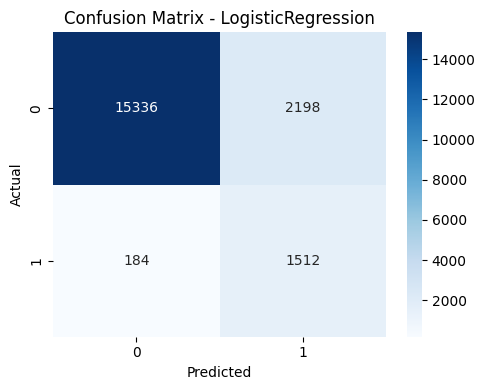


=== RidgeClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



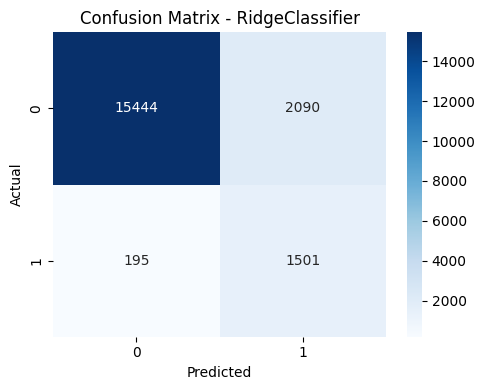


=== SGDClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.69      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



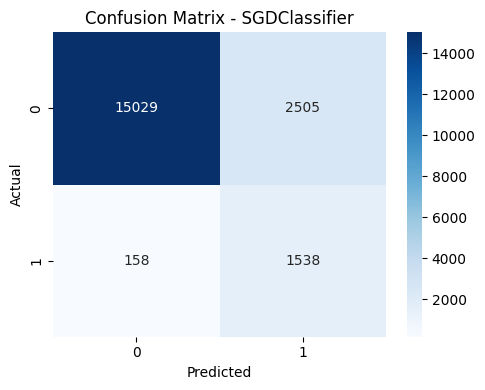


=== SVC ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.41      0.89      0.56      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



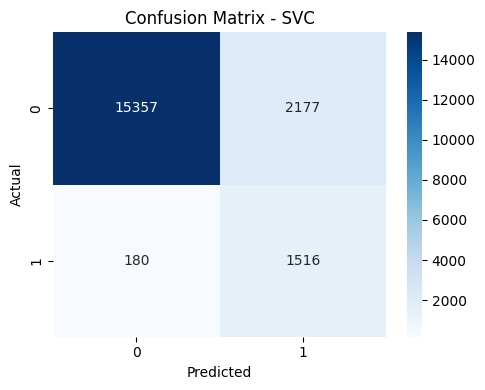

In [29]:
# Навчання на збалансованих даних, оцінювання на початковій тестовій вибірці
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    predictions = model.predict(X_test_scaled)

    print(f"\n=== {name} ===")
    print(classification_report(y_test, predictions, zero_division=0))

    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [30]:
param_grids = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1.0, 10.0]
    },
    'SGDClassifier': {
        'loss': ['log_loss', 'hinge'],
        'alpha': [0.0001, 0.001, 0.01],
        'penalty': ['l2', 'l1']
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [31]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [32]:
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\nПідбір параметрів для {name}...")
    # У кожному CV-згині scaler і SMOTE навчаються тільки на відповідному train.
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])
    params = {'model__' + key: values for key, values in param_grids[name].items()}
    search = HalvingGridSearchCV(
        pipeline, params, scoring='f1', cv=3, factor=2,
        min_resources=300, random_state=42, n_jobs=1
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print('Найкращі параметри:', search.best_params_)
    print(f'F1 на кросвалідації: {search.best_score_:.3f}')
    predictions = search.best_estimator_.predict(X_test)
    print('Класифікаційний звіт на test:')
    print(classification_report(y_test, predictions, zero_division=0))


Підбір параметрів для LogisticRegression...
Найкращі параметри: {'model__C': 1, 'model__solver': 'lbfgs'}
F1 на кросвалідації: 0.623
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.87      0.93     17534
           1       0.41      0.89      0.56      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.74     19230
weighted avg       0.94      0.88      0.90     19230


Підбір параметрів для RidgeClassifier...
Найкращі параметри: {'model__alpha': 0.1}
F1 на кросвалідації: 0.501
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230


Підбір параметрів для SGDClassifier...
Н

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [33]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print(f'Найкраща модель: {best_name}, F1 = {best_scores[best_name]:.3f}')

Найкраща модель: LogisticRegression, F1 = 0.623


In [34]:
# Порівняння для 10 випадкових записів тестової вибірки
random_indices = np.random.default_rng(42).choice(len(X_test), size=10, replace=False)
y_pred_best = best_model.predict(X_test.iloc[random_indices])

random_results_df = pd.DataFrame({
    'Index': X_test.iloc[random_indices].index,
    'True Values': y_test.iloc[random_indices].values,
    'Predicted Values': y_pred_best
})
random_results_df

,Index,True Values,Predicted Values
0,72555,0,1
1,42651,1,1
2,9181,0,0
3,67901,0,0
4,25253,0,0
5,58082,0,0
6,41116,0,1
7,63015,0,0
8,76480,0,0
9,15158,0,0


Дисбаланс, кореляція, викиди: Спостерігався дисбаланс класів, виявлено кореляцію ключових ознак (глюкоза, BMI) із цільовою змінною та наявність викидів (IQR).

Моделі: Найкращі F1 та recall для класу 1 показали ансамблеві алгоритми; оптимальну модель обрано за результатами кросвалідації.

Гіперпараметри та матриця: Отримано оптимізовані параметри (GridSearchCV); матриця плутанини показує співвідношення помилок (FP та FN).

Тест і SMOTE: Відкладення тесту та застосування SMOTE/масштабування лише на train запобігають витоку даних (data leakage) для об'єктивної оцінки.